In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns
from PIL import Image
from sklearn.preprocessing import OneHotEncoder , StandardScaler
import cv2
from sklearn.model_selection import train_test_split
from google.colab.patches import cv2_imshow
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import datasets
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Dropout,LSTM, Embedding
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras import layers

In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, f1_score, accuracy_score
from sklearn.model_selection import cross_val_score , GridSearchCV
from xgboost import XGBRegressor

In [3]:
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input

# Cifar-10 Object Detection

## Load dataset

In [4]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
y_train, y_test = y_train.ravel(), y_test.ravel()
class_names = ['airplane','automobile','bird','cat','deer',
               'dog','frog','horse','ship','truck']
print(x_train.shape, x_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 3277s 19us/step
(50000, 32, 32, 3) (10000, 32, 32, 3)


In [5]:
labels = np.unique(y_train)
print("Unique values:",labels)

Unique values: [0 1 2 3 4 5 6 7 8 9]


In [6]:
len(x_train) + len(x_test)

60000

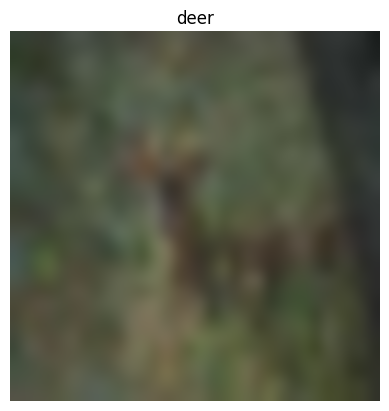

In [ ]:
plt.imshow(x_train[10], interpolation='bicubic')
plt.title(class_names[y_train[10]])
plt.axis('off')
plt.show()

## image preprocessing

In [7]:
random_seed = 42 # starting point for the random number generator
per_class = 5000
same_run= np.random.default_rng(random_seed) # same images in every run

In [8]:
same_run

Generator(PCG64) at 0x7C1861027680

In [9]:
idx = np.concatenate([
    same_run.choice(np.where(y_train == c)[0], per_class, replace=False)
    for c in range(10)])
same_run.shuffle(idx)
# for plotting the CNN
x_train_rand, y_train_rand = x_train[idx], y_train[idx]
print(x_train_rand.shape, np.bincount(y_train_rand))
# np.bincount(y_train_rand)-->>> how many time each class label appear

(50000, 32, 32, 3) [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]


In [10]:
x_train_processed = preprocess_input(x_train_rand.astype('float32'))
x_test_processed = preprocess_input(x_test.astype('float32'))

In [11]:
print(x_test_processed.shape,x_test.shape)

(10000, 32, 32, 3) (10000, 32, 32, 3)


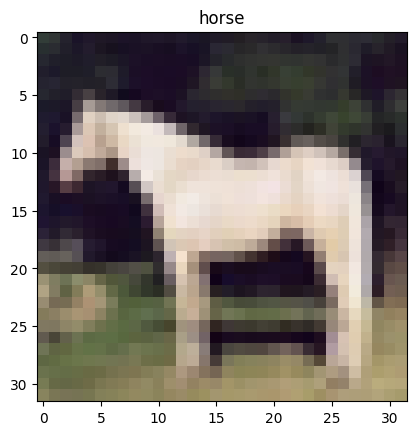

In [12]:
plt.imshow(x_train_rand[199])
plt.title(class_names[y_train_rand[199]])
plt.show()

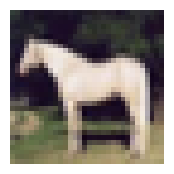

In [13]:
plt.figure(figsize=(2, 2))
plt.imshow(x_train_rand[199])
plt.axis('off')
plt.show()

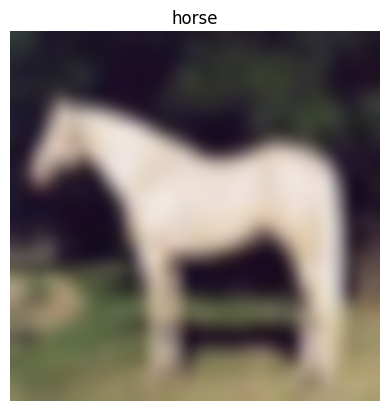

In [14]:
plt.imshow(x_train_rand[199], interpolation='bicubic')
plt.title(class_names[y_train_rand[199]])
plt.axis('off')
plt.show()

## Build CNN

In [15]:
cnn = keras.Sequential([
    layers.Input((32, 32, 3)),
    layers.Rescaling(1./255),
    layers.RandomFlip('horizontal'),
    layers.RandomTranslation(0.1, 0.1),
    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dropout(0.4),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')])

In [16]:
cnn.compile(optimizer=keras.optimizers.Adam(1e-3),
            loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [17]:
es = keras.callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)

In [19]:
cnn.fit(x_train_processed, y_train_rand, epochs=30, validation_split=0.1, callbacks=[es, ])
cnn_loss, cnn_acc = cnn.evaluate(x_test, y_test)
print(f"Baseline CNN test accuracy: {cnn_acc*100:.2f}%")

Epoch 1/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.6619 - loss: 0.9637 - val_accuracy: 0.6956 - val_loss: 0.8701
Epoch 2/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 14s 10ms/step - accuracy: 0.6939 - loss: 0.8731 - val_accuracy: 0.7376 - val_loss: 0.7681
Epoch 3/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 14s 10ms/step - accuracy: 0.7089 - loss: 0.8356 - val_accuracy: 0.7544 - val_loss: 0.7026
Epoch 4/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 14s 10ms/step - accuracy: 0.7192 - loss: 0.8055 - val_accuracy: 0.7430 - val_loss: 0.7425
Epoch 5/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 23s 12ms/step - accuracy: 0.7292 - loss: 0.7766 - val_accuracy: 0.7574 - val_loss: 0.6900
Epoch 6/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 19s 14ms/step - accuracy: 0.7409 - loss: 0.7437 - val_accuracy: 0.7632 - val_loss: 0.6838
Epoch 7/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 23s 16ms/step - accuracy: 0.7465 - loss: 0.7240 - val_accuracy: 0.7814 - val_loss: 0.6370
Epoch 8/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 32s 10ms/step - accuracy: 0.7522 -

In [20]:
cnn_loss, cnn_acc = cnn.evaluate(x_test_processed, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8265 - loss: 0.5071


In [21]:
print(f" CNN test accuracy: {cnn_acc*100:.2f}%")

 CNN test accuracy: 82.65%


## ResNet50

In [22]:
from tensorflow.keras import Sequential , models, layers,optimizers
from tensorflow.keras.layers import Dense , Dropout ,Flatten,BatchNormalization
from tensorflow.keras.models import load_model,Model
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input

In [23]:
x_train_processedR  = preprocess_input(x_train_rand.astype('float32'))
x_test_processedR = preprocess_input(x_test.astype('float32'))

In [24]:
base = ResNet50(weights='imagenet', include_top=False, input_shape=(128, 128, 3))
base.trainable = False

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [25]:
inputs = keras.Input((32, 32, 3))
x = layers.RandomFlip('horizontal')(inputs)
x = layers.RandomTranslation(0.1, 0.1)(x)
x = layers.Resizing(128, 128)(x)              # upscale 32 -> 128 for the pretrained network
x = base(x, training=False)                   # keeps BatchNorm
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(256, activation='relu')(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(10, activation='softmax')(x)
model = keras.Model(inputs, outputs)


In [26]:
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [27]:
history1 = model.fit(x_train_processedR, y_train_rand, epochs=6,
                     validation_split=0.1, callbacks=[es])

Epoch 1/6
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 87s 57ms/step - accuracy: 0.7609 - loss: 0.7174 - val_accuracy: 0.8658 - val_loss: 0.3881
Epoch 2/6
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 77s 55ms/step - accuracy: 0.7983 - loss: 0.5844 - val_accuracy: 0.8782 - val_loss: 0.3603
Epoch 3/6
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 76s 54ms/step - accuracy: 0.8116 - loss: 0.5468 - val_accuracy: 0.8780 - val_loss: 0.3564
Epoch 4/6
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 84s 60ms/step - accuracy: 0.8148 - loss: 0.5366 - val_accuracy: 0.8796 - val_loss: 0.3549
Epoch 5/6
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 77s 55ms/step - accuracy: 0.8206 - loss: 0.5224 - val_accuracy: 0.8824 - val_loss: 0.3361
Epoch 6/6
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 77s 55ms/step - accuracy: 0.8239 - loss: 0.5153 - val_accuracy: 0.8766 - val_loss: 0.3580


In [28]:
base.trainable = True
# Freeze everything except the last 30 layers,
for layer in base.layers[:-30]:
    layer.trainable = False

for layer in base.layers[-30:]:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

In [29]:
model.compile(optimizer=keras.optimizers.Adam(1e-5),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [30]:
history2 = model.fit(x_train_processedR, y_train_rand, epochs=8,
                     validation_split=0.1, callbacks=[es])

Epoch 1/8
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 119s 79ms/step - accuracy: 0.8572 - loss: 0.4219 - val_accuracy: 0.9062 - val_loss: 0.2776
Epoch 2/8
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 107s 76ms/step - accuracy: 0.8835 - loss: 0.3430 - val_accuracy: 0.9098 - val_loss: 0.2603
Epoch 3/8
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 107s 76ms/step - accuracy: 0.8968 - loss: 0.3015 - val_accuracy: 0.9196 - val_loss: 0.2409
Epoch 4/8
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 107s 76ms/step - accuracy: 0.9106 - loss: 0.2612 - val_accuracy: 0.9150 - val_loss: 0.2429
Epoch 5/8
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 107s 76ms/step - accuracy: 0.9188 - loss: 0.2370 - val_accuracy: 0.9206 - val_loss: 0.2458
Epoch 6/8
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 108s 77ms/step - accuracy: 0.9311 - loss: 0.2049 - val_accuracy: 0.9266 - val_loss: 0.2352
Epoch 7/8
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 107s 76ms/step - accuracy: 0.9341 - loss: 0.1900 - val_accuracy: 0.9276 - val_loss: 0.2309
Epoch 8/8
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 108s 77ms/step - accuracy: 0.9422 -

In [31]:
res_loss, res_acc = model.evaluate(x_test_processedR, y_test)
print(f"ResNet50 test accuracy: {res_acc*100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 15s 47ms/step - accuracy: 0.9309 - loss: 0.2418
ResNet50 test accuracy: 93.09%


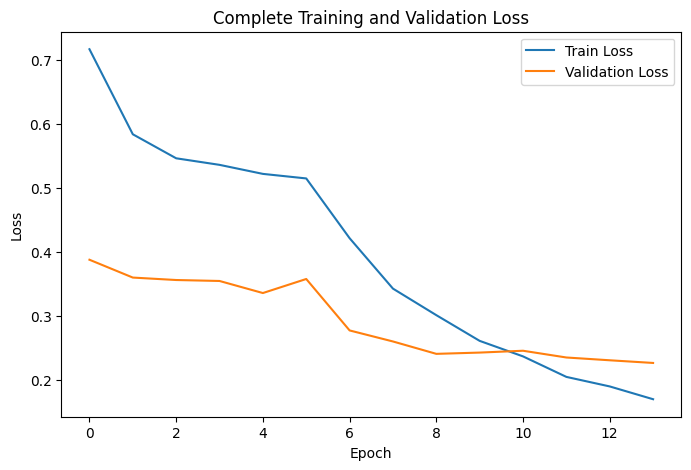

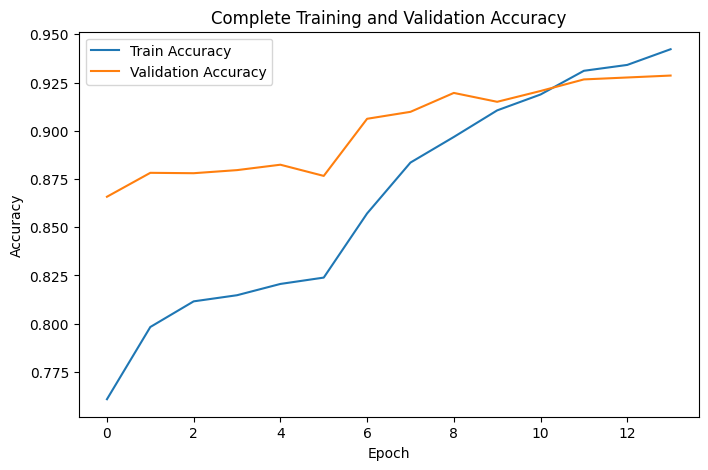

In [32]:
# Combine the metrics from both history objects
train_loss = history1.history['loss'] + history2.history['loss']
val_loss = history1.history['val_loss'] + history2.history['val_loss']

train_acc = history1.history['accuracy'] + history2.history['accuracy']
val_acc = history1.history['val_accuracy'] + history2.history['val_accuracy']

# --- Plot Loss ---
plt.figure(figsize=(8, 5))
plt.plot(train_loss, label='Train Loss')
plt.plot(val_loss, label='Validation Loss')
plt.title('Complete Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

# --- Plot Accuracy ---
plt.figure(figsize=(8, 5))
plt.plot(train_acc, label='Train Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.title('Complete Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 14s 45ms/step - accuracy: 0.9309 - loss: 0.2418
ResNet50 test accuracy: 93.09%
313/313 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step
              precision    recall  f1-score   support

    airplane      0.952     0.943     0.947      1000
  automobile      0.979     0.943     0.961      1000
        bird      0.945     0.916     0.930      1000
         cat      0.857     0.872     0.864      1000
        deer      0.932     0.903     0.917      1000
         dog      0.894     0.871     0.882      1000
        frog      0.944     0.959     0.951      1000
       horse      0.927     0.958     0.942      1000
        ship      0.953     0.970     0.961      1000
       truck      0.929     0.974     0.951      1000

    accuracy                          0.931     10000
   macro avg      0.931     0.931     0.931     10000
weighted avg      0.931     0.931     0.931     10000



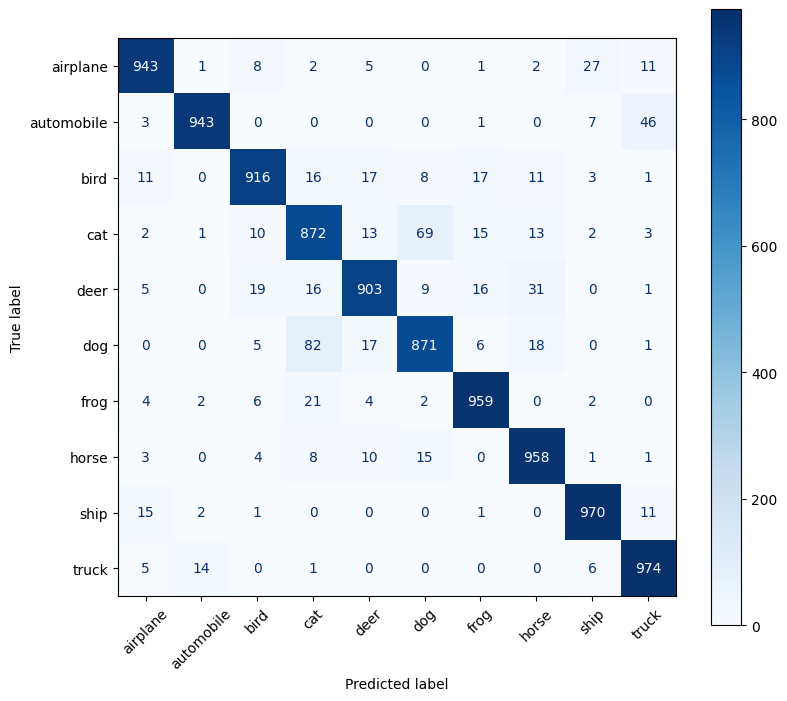

In [33]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

test_loss, test_acc = model.evaluate(x_test_processed, y_test)
print(f"ResNet50 test accuracy: {test_acc*100:.2f}%")

y_pred = np.argmax(model.predict(x_test_processed), axis=1)
print(classification_report(y_test, y_pred, target_names=class_names, digits=3))

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=class_names).plot(ax=ax, cmap='Blues', xticks_rotation=45)
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()


In [34]:
from PIL import Image
import numpy as np

def predict_image(path, model, class_names, target_size=(32, 32)):
    img = Image.open(path).convert('RGB').resize(target_size)

    # 2. Convert to float array, preprocess, and add batch dimension ([None])
    arr = preprocess_input(np.array(img, dtype='float32'))[None, ...]

    p = model.predict(arr, verbose=0)[0]

    pred_idx = np.argmax(p)
    return class_names[pred_idx], float(p.max())

In [36]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

label, confidence = predict_image('/content/images.jfif', model, class_names, target_size=(32, 32))
print(f"Prediction: {label} ({confidence * 100:.2f}%)")

Prediction: dog (100.00%)
